# Assignment 3 — Building the Pricing Library

Starting files: `Lectures/2026_fall_BME/05_BuildingBlocks/solution`.

## 3(a) Digital options

**Task:** Implement `EuropeanDigitalContract` and `EuropeanDigitalAnalyticPricer`, including fair value and Greeks. Add a pytest fair-value test.

**Solution:** `contract.py`, `pricer.py` and `test_digital.py`.

Unit cash-or-nothing payoff:

$$H_{call}=1_{\{S_T>K\}},\qquad H_{put}=1_{\{S_T<K\}}.$$

For $\tau=T-t>0$, $D=e^{-r\tau}$, $b=\sigma\sqrt\tau$, and $q=+1$ for calls or $-1$ for puts:

$$d_1=\frac{\log(S/K)+(r+\sigma^2/2)\tau}{\sigma\sqrt\tau},\qquad d_2=d_1-b,\qquad V=DN(qd_2).$$

$$\Delta=\frac{qD\phi(d_2)}{Sb},\qquad
\Gamma=-\frac{qD\phi(d_2)}{S^2b}\left(1+\frac{d_2}{b}\right),\qquad
\mathcal V=-\frac{qD\phi(d_2)d_1}{\sigma}.$$

$$\Theta=rV-qD\phi(d_2)\left[\frac{r-\sigma^2/2}{\sigma\sqrt\tau}-\frac{d_2}{2\tau}\right],\qquad
\rho=-\tau V+\frac{qD\phi(d_2)\sqrt\tau}{\sigma}.$$

No dividends; constant rate and volatility. Vega and rho are per unit input change; theta is per year of calendar time. Short positions multiply payoffs and all measures by $-1$. Both payoffs are zero at $S_T=K$.

References: [cash-or-nothing payoff](https://github.com/lballabio/QuantLib/blob/master/ql/instruments/payoffs.cpp), [scaled-spread limit, p. 54](https://booksite.elsevier.com/samplechapters/9780120476824/9780120476824.PDF#page=54).

In [1]:
import sys
from pathlib import Path
# Support opening this notebook from its own folder or the repository root,
# including after relocation under homeworks/<personal-id>/assignment_3.
cwd = Path.cwd().resolve()
repo = next((p for p in [cwd, *cwd.parents] if (p/'src/enums.py').is_file()), None)
if repo is None:
    raise RuntimeError('Open this notebook from inside QuantCourseBP.')
if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))
if (cwd/'contract.py').is_file() and (cwd/'__init__.py').is_file():
    assignment_folder = cwd
else:
    assignment_folder = repo/'homeworks/83019cd/assignment_3'
if str(assignment_folder.parent) not in sys.path:
    sys.path.insert(0, str(assignment_folder.parent))

import numpy as np
import matplotlib.pyplot as plt
from copy import deepcopy
from assignment_3.contract import EuropeanContract, EuropeanDigitalContract
from assignment_3.model import MarketModel
from assignment_3.pricer import EuropeanAnalyticPricer, EuropeanDigitalAnalyticPricer, Params
from src.enums import Stock, PutCallFwd, LongShort

underlying = Stock.BLUECHIP_BANK
model = MarketModel(underlying)
# Controlled example inputs; copied lecture market data is unchanged.
model.spot, model.vol, model.risk_free_rate = 100., .2, .05
strike, expiry = 100., 1.
call_contract = EuropeanDigitalContract(underlying, PutCallFwd.CALL, LongShort.LONG, strike, expiry)
put_contract = EuropeanDigitalContract(underlying, PutCallFwd.PUT, LongShort.LONG, strike, expiry)
call = EuropeanDigitalAnalyticPricer(call_contract, model, Params())
put = EuropeanDigitalAnalyticPricer(put_contract, model, Params())
print('Inputs: spot=strike=100, T=1 year, annual r=5%, sigma=20%, unit payout')
for name in ['fair_value', 'delta', 'gamma', 'vega', 'theta', 'rho']:
    print(f'{name:>10}: call={getattr(call, "calc_"+name)(): .10f}, '
          f'put={getattr(put, "calc_"+name)(): .10f}')
print(f'Call + put price: {call.calc_fair_value()+put.calc_fair_value():.10f}')
print(f'Discounted unit:  {model.calc_df(expiry):.10f}')
np.testing.assert_allclose(call.calc_fair_value()+put.calc_fair_value(), model.calc_df(expiry), atol=1e-12)
for terminal_spot in [90., 100., 110.]:
    print(f'S_T={terminal_spot:.0f}: call payoff={call_contract.payoff({expiry: terminal_spot}):.0f}, '
          f'put payoff={put_contract.payoff({expiry: terminal_spot}):.0f}')

QuantCourseBP 7d165ec7c4cc50b151e51e6c36bbd898a31b115b*
Inputs: spot=strike=100, T=1 year, annual r=5%, sigma=20%, unit payout
fair_value: call= 0.5323248155, put= 0.4189046090
     delta: call= 0.0187620173, put=-0.0187620173
     gamma: call=-0.0003283353, put= 0.0003283353
      vega: call=-0.6566706071, put= 0.6566706071
     theta: call=-0.0015267852, put= 0.0490882565
       rho: call= 1.3438769191, put=-2.2951063436
Call + put price: 0.9512294245
Discounted unit:  0.9512294245
S_T=90: call payoff=0, put payoff=1
S_T=100: call payoff=0, put payoff=0
S_T=110: call payoff=1, put payoff=0


## 3(b) Digital call as a bull-spread limit

**Task:** Use `EuropeanDigitalAnalyticPricer` and `EuropeanAnalyticPricer` to plot convergence of increasingly narrow bull call spreads to a digital call.

**Solution:** Long $1/h$ calls at strike $K$ and short $1/h$ calls at strike $K+h$.

$$B_h(S_T)=\frac{(S_T-K)^+-(S_T-K-h)^+}{h}\xrightarrow{h\downarrow0}1_{\{S_T>K\}},$$
$$\frac{C(S,K)-C(S,K+h)}{h}\xrightarrow{h\downarrow0}-\frac{\partial C}{\partial K}=e^{-r\tau}N(d_2).$$

$K=100$, $T=1$, $r=0.05$, $\sigma=0.20$, $h\in\{10,5,1,0.1\}$.

Width    Spread price at S=100     Digital price       Maximum grid error
   10         0.4410495442             0.5323248155         9.128e-02
    5         0.4858462674             0.5323248155         4.659e-02
    1         0.5229535393             0.5323248155         9.455e-03
  0.1         0.5313867947             0.5323248155         9.484e-04


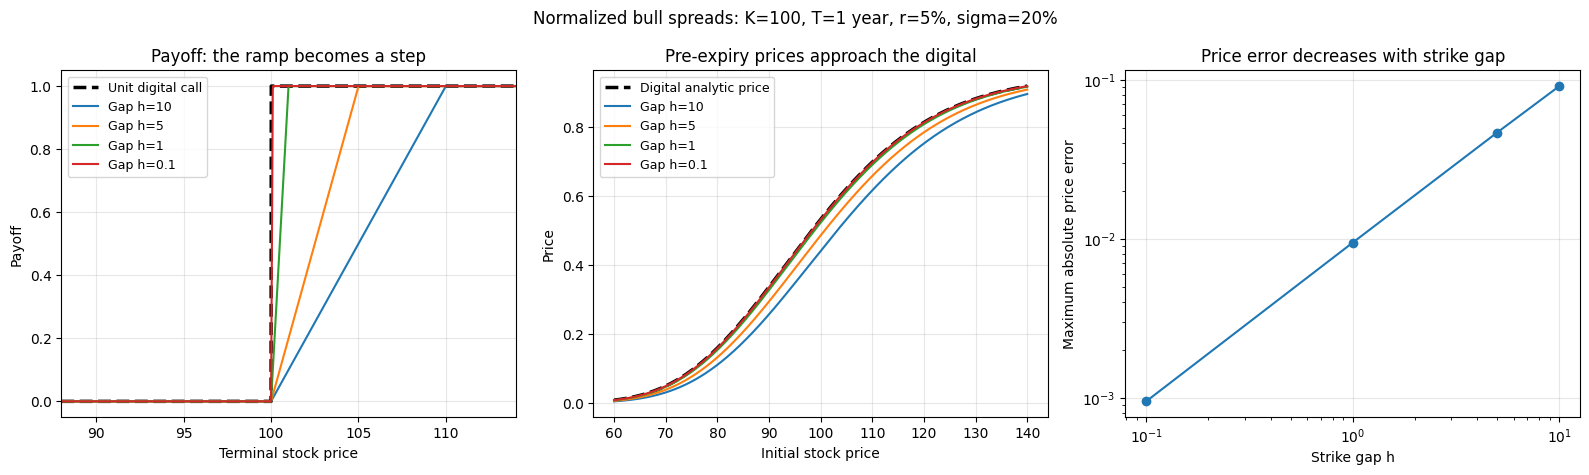

In [2]:
widths = [10., 5., 1., .1]
spots = np.linspace(60., 140., 401)
terminal_spots = np.unique(np.r_[np.linspace(88., 114., 1501), strike])
timeline = call_contract.get_timeline()[0]

def vanilla_pricer(K, position, spot):
    local_model = deepcopy(model)
    local_model.spot = spot
    contract = EuropeanContract(underlying, PutCallFwd.CALL, position, K, expiry)
    return EuropeanAnalyticPricer(contract, local_model, Params())

# Calculate the digital curve with the new analytic pricer.
digital_prices = []
for spot in spots:
    local_model = deepcopy(model)
    local_model.spot = spot
    digital_prices.append(EuropeanDigitalAnalyticPricer(call_contract, local_model, Params()).calc_fair_value())
digital_prices = np.array(digital_prices)
digital_payoffs = np.array([call_contract.payoff({timeline: s}) for s in terminal_spots])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
axes[0].plot(terminal_spots, digital_payoffs, 'k--', linewidth=2.5, label='Unit digital call')
axes[1].plot(spots, digital_prices, 'k--', linewidth=2.5, label='Digital analytic price')
max_errors = []
print('Width    Spread price at S=100     Digital price       Maximum grid error')
for width in widths:
    lower = vanilla_pricer(strike, LongShort.LONG, model.spot)
    upper = vanilla_pricer(strike+width, LongShort.SHORT, model.spot)
    payoff = np.array([(lower.contract.payoff({timeline: s})+upper.contract.payoff({timeline: s}))/width
                       for s in terminal_spots])
    prices = np.array([(vanilla_pricer(strike, LongShort.LONG, s).calc_fair_value()
                       + vanilla_pricer(strike+width, LongShort.SHORT, s).calc_fair_value())/width for s in spots])
    axes[0].plot(terminal_spots, payoff, label=f'Gap h={width:g}')
    axes[1].plot(spots, prices, label=f'Gap h={width:g}')
    max_error = np.max(np.abs(prices-digital_prices))
    max_errors.append(max_error)
    at_spot = (lower.calc_fair_value()+upper.calc_fair_value())/width
    print(f'{width:5g}         {at_spot:.10f}             {call.calc_fair_value():.10f}         {max_error:.3e}')
assert np.all(np.diff(max_errors) < 0)
assert max_errors[-1] < .002
axes[0].set(title='Payoff: the ramp becomes a step', xlabel='Terminal stock price', ylabel='Payoff')
axes[0].set_xlim(88, 114)
axes[1].set(title='Pre-expiry prices approach the digital', xlabel='Initial stock price', ylabel='Price')
axes[2].loglog(widths, max_errors, 'o-')
axes[2].set(title='Price error decreases with strike gap', xlabel='Strike gap h', ylabel='Maximum absolute price error')
for ax in axes[:2]:
    ax.legend(fontsize=9)
for ax in axes:
    ax.grid(True, alpha=.3)
fig.suptitle('Normalized bull spreads: K=100, T=1 year, r=5%, sigma=20%')
fig.tight_layout()
plt.show()